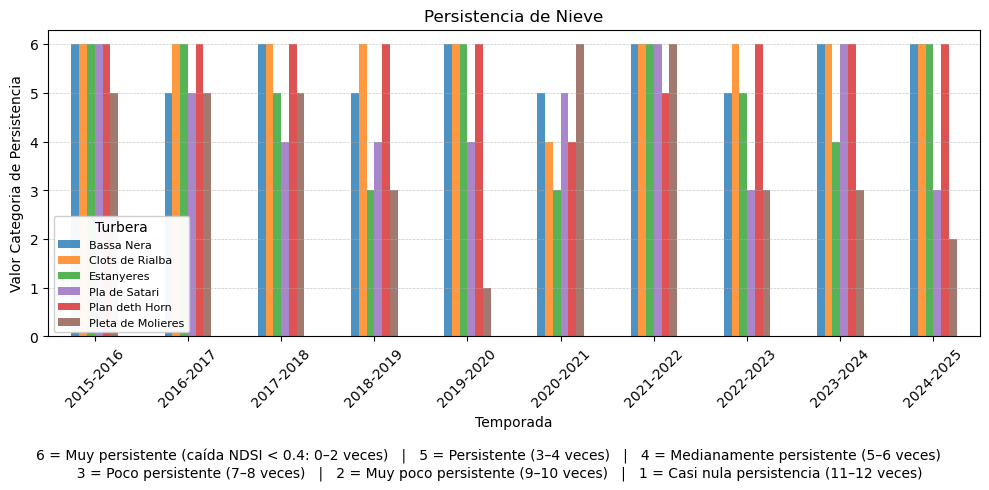

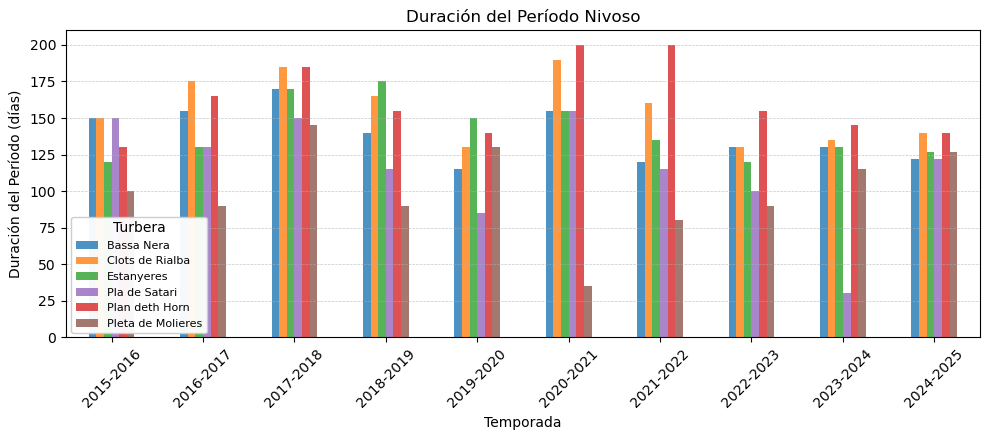

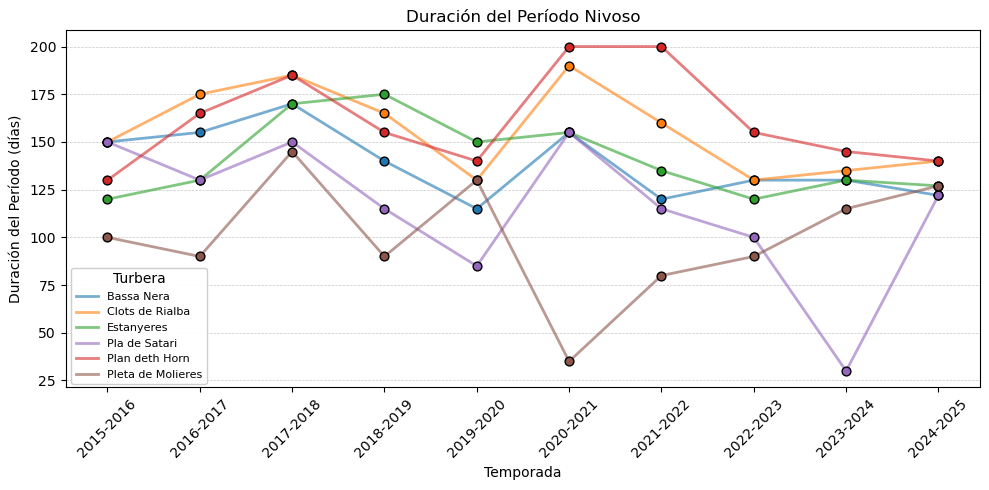

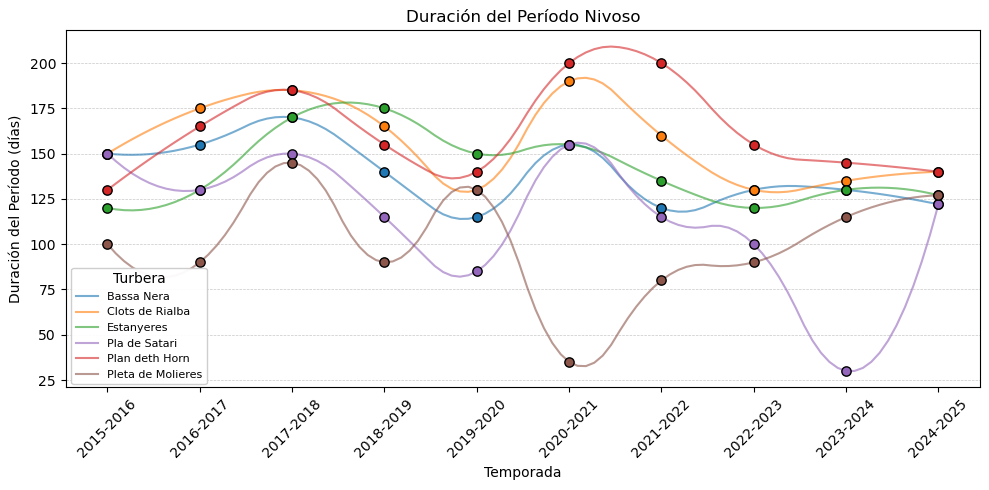

In [49]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Directorio con los CSV
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDSI"

# Leer todos los CSV y combinarlos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDSI.csv"):
        nombre = file.replace("_analisis_NDSI.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Pivotear la tabla para facilitar el gráfico
pivot = df_total.pivot(index="Temporada", columns="Turbera", values="Valor Categoria")

# Colores fijos por turbera (ajusta si cambias nombres)
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Crear gráfico
ax = pivot.plot(kind="bar", figsize=(10, 5), color=[colores[col] for col in pivot.columns], alpha=0.8)

# Ejes y título
plt.title("Persistencia de Nieve")
plt.xlabel("Temporada")
plt.ylabel("Valor Categoria de Persistencia")
plt.xticks(rotation=45)
# Mostrar cuadrícula horizontal punteada
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda dentro del gráfico (a la izquierda)
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.41),
    fontsize=8,
    frameon=True,
    framealpha=0.95  # 1← fondo totalmente opaco
)


# Ajustar layout para que no corte la leyenda
plt.tight_layout(rect=[0, 0.1, 1, 1])  # Dejar espacio abajo

# Texto explicativo
plt.figtext(
    0.5, 0.04,
    "6 = Muy persistente (caída NDSI < 0.4: 0–2 veces)   |   "
    "5 = Persistente (3–4 veces)   |   "
    "4 = Medianamente persistente (5–6 veces)   \n  "
    "3 = Poco persistente (7–8 veces)   |   "
    "2 = Muy poco persistente (9–10 veces)   |   "
    "1 = Casi nula persistencia (11–12 veces)",
    wrap=True, ha='center', fontsize=10
)


# Guardar
#plt.savefig(os.path.join(input_dir, "grafico_persistencia_turberas.png"), dpi=150)
plt.savefig(os.path.join(input_dir, "grafico_persistencia_turberas.png"), dpi=150, bbox_inches='tight')
plt.show()


#----------------------------------------------------
# Segundo gráfico: duración del período de nieve (columna "Periodo")
#----------------------------------------------------

import matplotlib.pyplot as plt

# Pivotear para gráfico de duración
pivot_duracion = df_total.pivot(index="Temporada", columns="Turbera", values="Periodo")

# Crear figura
fig, ax = plt.subplots(figsize=(10, 5))

# Dibujar barras agrupadas
pivot_duracion.plot(
    kind='bar',
    ax=ax,
    color=[colores[col] for col in pivot_duracion.columns],
    alpha=0.8,
    width=0.5
)

# Etiquetas y título
ax.set_title("Duración del Período Nivoso")
ax.set_xlabel("Temporada")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
ax.set_ylabel("Duración del Período (días)")
ax.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left')

# Leyenda dentro del gráfico (a la izquierda)
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.41),
    fontsize=8,
    frameon=True,
    framealpha=0.95  # 1← fondo totalmente opaco
)

# Cuadrícula horizontal
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Ajustar layout para evitar que se corte la leyenda
plt.tight_layout(rect=[0, 0.1, 1, 1])  # Dejar espacio abajo

# Guardar imagen
#plt.savefig(os.path.join(input_dir, "grafico_duracion_nieve_turberas.png"), dpi=150)
plt.savefig(os.path.join(input_dir, "grafico_duracion_nieve_turberas.png"), dpi=150, bbox_inches='tight')
plt.show()

#----------------------------------------------------
# Tercer gráfico: duración del período de nieve (columna "Periodo") LINEAS
#----------------------------------------------------

# Gráfico de líneas: duración del período de nieve por temporada y turbera
fig, ax = plt.subplots(figsize=(10, 5))

# Dibujar cada serie: línea + puntos por separado
for turbera in pivot_duracion.columns:
    # Línea con transparencia
    ax.plot(
        pivot_duracion.index,
        pivot_duracion[turbera],
        label=turbera,
        color=colores.get(turbera, None),
        linewidth=2,
        alpha=0.6
    )
    # Puntos sin transparencia
    ax.scatter(
        pivot_duracion.index,
        pivot_duracion[turbera],
        color=colores.get(turbera, None),
        edgecolor='black',
        zorder=3,
        alpha=1,
        s=40
    )
    
# Título y etiquetas
ax.set_title("Duración del Período Nivoso")
ax.set_xlabel("Temporada")
ax.set_ylabel("Duración del Período (días)")
ax.set_xticks(pivot_duracion.index)
ax.set_xticklabels(pivot_duracion.index, rotation=45)

# Cuadrícula
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)


# Leyenda dentro del gráfico (a la izquierda)
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.35),
    fontsize=8,
    frameon=True,
    framealpha=0.95  # 1← fondo totalmente opaco
)

# Ajustar y guardar
plt.tight_layout()
#plt.savefig(os.path.join(input_dir, "grafico_duracion_nieve_lineas_turberas.png"), dpi=150)
plt.savefig(os.path.join(input_dir, "grafico_duracion_nieve_lineas_turberas.png"), dpi=150, bbox_inches='tight')
plt.show()

#----------------------------------------------------
# Tercer gráfico: duración del período de nieve (columna "Periodo") LINEAS suavizadas
#----------------------------------------------------

from scipy.interpolate import make_interp_spline
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5))

# Convertir las temporadas a valores numéricos temporales
x_numeric = np.arange(len(pivot_duracion.index))
x_labels = pivot_duracion.index

# Dibujar cada turbera con suavizado
for turbera in pivot_duracion.columns:
    y = pivot_duracion[turbera].values

    # Evitar errores por datos faltantes
    mask = ~np.isnan(y)
    x_vals = x_numeric[mask]
    y_vals = y[mask]

    if len(x_vals) >= 4:  # Se necesitan al menos 4 puntos para una spline cúbica
        spline = make_interp_spline(x_vals, y_vals, k=2)
        x_smooth = np.linspace(x_vals.min(), x_vals.max(), 100)
        y_smooth = spline(x_smooth)

        ax.plot(x_smooth, y_smooth, color=colores.get(turbera, None), label=turbera, alpha=0.6)
    else:
        ax.plot(x_vals, y_vals, color=colores.get(turbera, None), label=turbera, alpha=0.6)

    # Puntos originales
    ax.scatter(x_vals, y_vals, color=colores.get(turbera, None), edgecolor='black', zorder=3, s=45)

# Ejes y etiquetas
ax.set_title("Duración del Período Nivoso")
ax.set_xlabel("Temporada")
ax.set_ylabel("Duración del Período (días)")
ax.set_xticks(x_numeric)
ax.set_xticklabels(x_labels, rotation=45)

# Cuadrícula y leyenda
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)
# Leyenda dentro del gráfico (a la izquierda)
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.35),
    fontsize=8,
    frameon=True,
    framealpha=0.95  # 1← fondo totalmente opaco
)

# Ajustar y guardar
plt.tight_layout()
#plt.savefig(os.path.join(input_dir, "grafico_duracion_nieve_lineas_suavizadas_turberas.png"), dpi=150)
plt.savefig(os.path.join(input_dir, "grafico_duracion_nieve_lineas_suavizadas_turberas.png"), dpi=150, bbox_inches='tight')
plt.show()


#--------------------
# repetir graficos pero con porcentaje
#------------------------

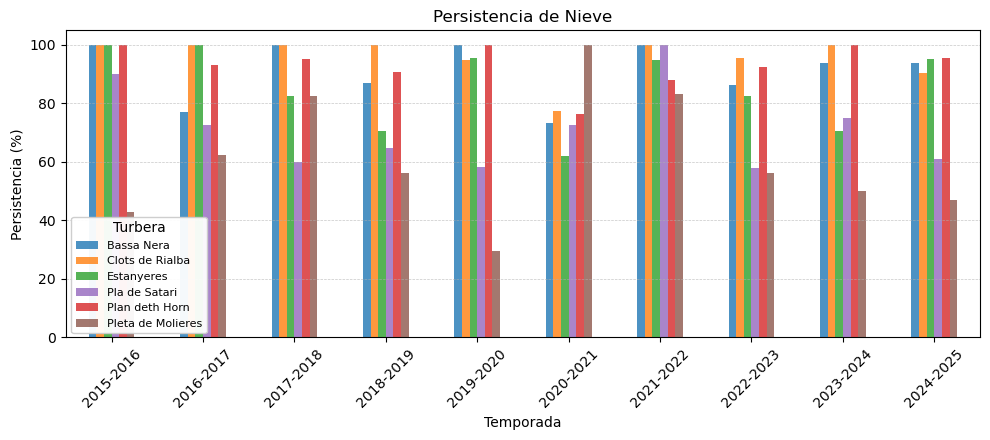

In [7]:
#--------------------
# repetir graficos pero con porcentaje
#------------------------

import os
import pandas as pd
import matplotlib.pyplot as plt

# Directorio con los CSV
input_dir = r"M:\material_isa\estadisticos\_Turberas\indices_analisis_NDSI"

# Leer todos los CSV y combinarlos
dfs = []
for file in os.listdir(input_dir):
    if file.endswith("_analisis_NDSI_v2.csv"):
        nombre = file.replace("_analisis_NDSI_v2.csv", "").replace("_", " ")
        df = pd.read_csv(os.path.join(input_dir, file), sep=";")
        df["Turbera"] = nombre
        dfs.append(df)

df_total = pd.concat(dfs)

# Pivotear la tabla para facilitar el gráfico
pivot = df_total.pivot(index="Temporada", columns="Turbera", values="Persistencia (%)")

# Colores fijos por turbera (ajusta si cambias nombres)
colores = {
    "Bassa Nera": "#1f77b4",
    "Clots de Rialba": "#ff7f0e",
    "Estanyeres": "#2ca02c",
    "Pla de Sartari": "#9467bd",
    "Plan deth Horn": "#d62728",
    "Pleta de Molieres": "#8c564b"
}

# Crear gráfico
ax = pivot.plot(kind="bar", figsize=(10, 5), color=[colores[col] for col in pivot.columns], alpha=0.8)

# Ejes y título
plt.title("Persistencia de Nieve")
plt.xlabel("Temporada")
plt.ylabel("Persistencia (%)")
plt.xticks(rotation=45)
# Mostrar cuadrícula horizontal punteada
plt.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.7)

# Leyenda dentro del gráfico (a la izquierda)
plt.legend(title="Turbera", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
ax.legend(
    title="Turbera",
    loc="upper left",
    bbox_to_anchor=(0, 0.41),
    fontsize=8,
    frameon=True,
    framealpha=0.95  # 1← fondo totalmente opaco
)


# Ajustar layout para que no corte la leyenda
plt.tight_layout(rect=[0, 0.1, 1, 1])  # Dejar espacio abajo

# Texto explicativo
#plt.figtext(
#    0.5, 0.04,
#    "6 = Muy persistente (caída NDSI < 0.4: 0–2 veces)   |   "
#    "5 = Persistente (3–4 veces)   |   "
#    "4 = Medianamente persistente (5–6 veces)   \n  "
#    "3 = Poco persistente (7–8 veces)   |   "
#    "2 = Muy poco persistente (9–10 veces)   |   "
#    "1 = Casi nula persistencia (11–12 veces)",
#    wrap=True, ha='center', fontsize=10
#)


# Guardar
#plt.savefig(os.path.join(input_dir, "grafico_persistencia_turberas.png"), dpi=150)
plt.savefig(os.path.join(input_dir, "grafico_persistencia_turberas_v2.png"), dpi=150, bbox_inches='tight')
plt.show()